In [7]:
import kagglehub

# Downloads the Instacart dataset straight into Colab's fast cloud disk (takes ~15-30 seconds)
path = kagglehub.dataset_download("psparks/instacart-market-basket-analysis")
print("Dataset downloaded to:", path)

# Set DATA_PATH automatically with trailing slash
DATA_PATH = path + "/"

Using Colab cache for faster access to the 'instacart-market-basket-analysis' dataset.
Dataset downloaded to: /kaggle/input/instacart-market-basket-analysis


**Load Tables with memory optimization**

> # 01.instacart_EDA & DATA_prep



In [8]:
import pandas as pd
import numpy as np
import gc

# Mount Google Drive if your dataset is stored there
# from google.colab import drive
# drive.mount('/content/drive')

import kagglehub
DATA_PATH = kagglehub.dataset_download("psparks/instacart-market-basket-analysis") + "/"
#DATA_PATH = "/content/"  # Update to your folder path, e.g., "/content/drive/MyDrive/instacart/"

# Define memory-efficient dtypes before loading
dtypes_orders = {
    'order_id': 'int32',
    'user_id': 'int32',
    'eval_set': 'category',
    'order_number': 'int16',
    'order_dow': 'int8',
    'order_hour_of_day': 'int8',
    'days_since_prior_order': 'float32'
}

dtypes_order_products = {
    'order_id': 'int32',
    'product_id': 'int32',
    'add_to_cart_order': 'int16',
    'reordered': 'int8'
}

dtypes_products = {
    'product_id': 'int32',
    'aisle_id': 'int16',
    'department_id': 'int8'
}

orders = pd.read_csv(f"{DATA_PATH}orders.csv", dtype=dtypes_orders)
prior = pd.read_csv(f"{DATA_PATH}order_products__prior.csv", dtype=dtypes_order_products)
train = pd.read_csv(f"{DATA_PATH}order_products__train.csv", dtype=dtypes_order_products)
products = pd.read_csv(f"{DATA_PATH}products.csv", dtype=dtypes_products)
aisles = pd.read_csv(f"{DATA_PATH}aisles.csv")
departments = pd.read_csv(f"{DATA_PATH}departments.csv")

print(f"Orders shape: {orders.shape} | Memory: {orders.memory_usage().sum() / 1e6:.1f} MB")
print(f"Prior shape:  {prior.shape}  | Memory: {prior.memory_usage().sum() / 1e6:.1f} MB")
print(f"Train shape:  {train.shape}  | Memory: {train.memory_usage().sum() / 1e6:.1f} MB")

Using Colab cache for faster access to the 'instacart-market-basket-analysis' dataset.
Orders shape: (3421083, 7) | Memory: 58.2 MB
Prior shape:  (32434489, 4)  | Memory: 356.8 MB
Train shape:  (1384617, 4)  | Memory: 15.2 MB


--- Missing Values in Orders ---
order_id                       0
user_id                        0
eval_set                       0
order_number                   0
order_dow                      0
order_hour_of_day              0
days_since_prior_order    206209
dtype: int64

Prior Reorder Rate: 58.97%
Train Reorder Rate: 59.86%


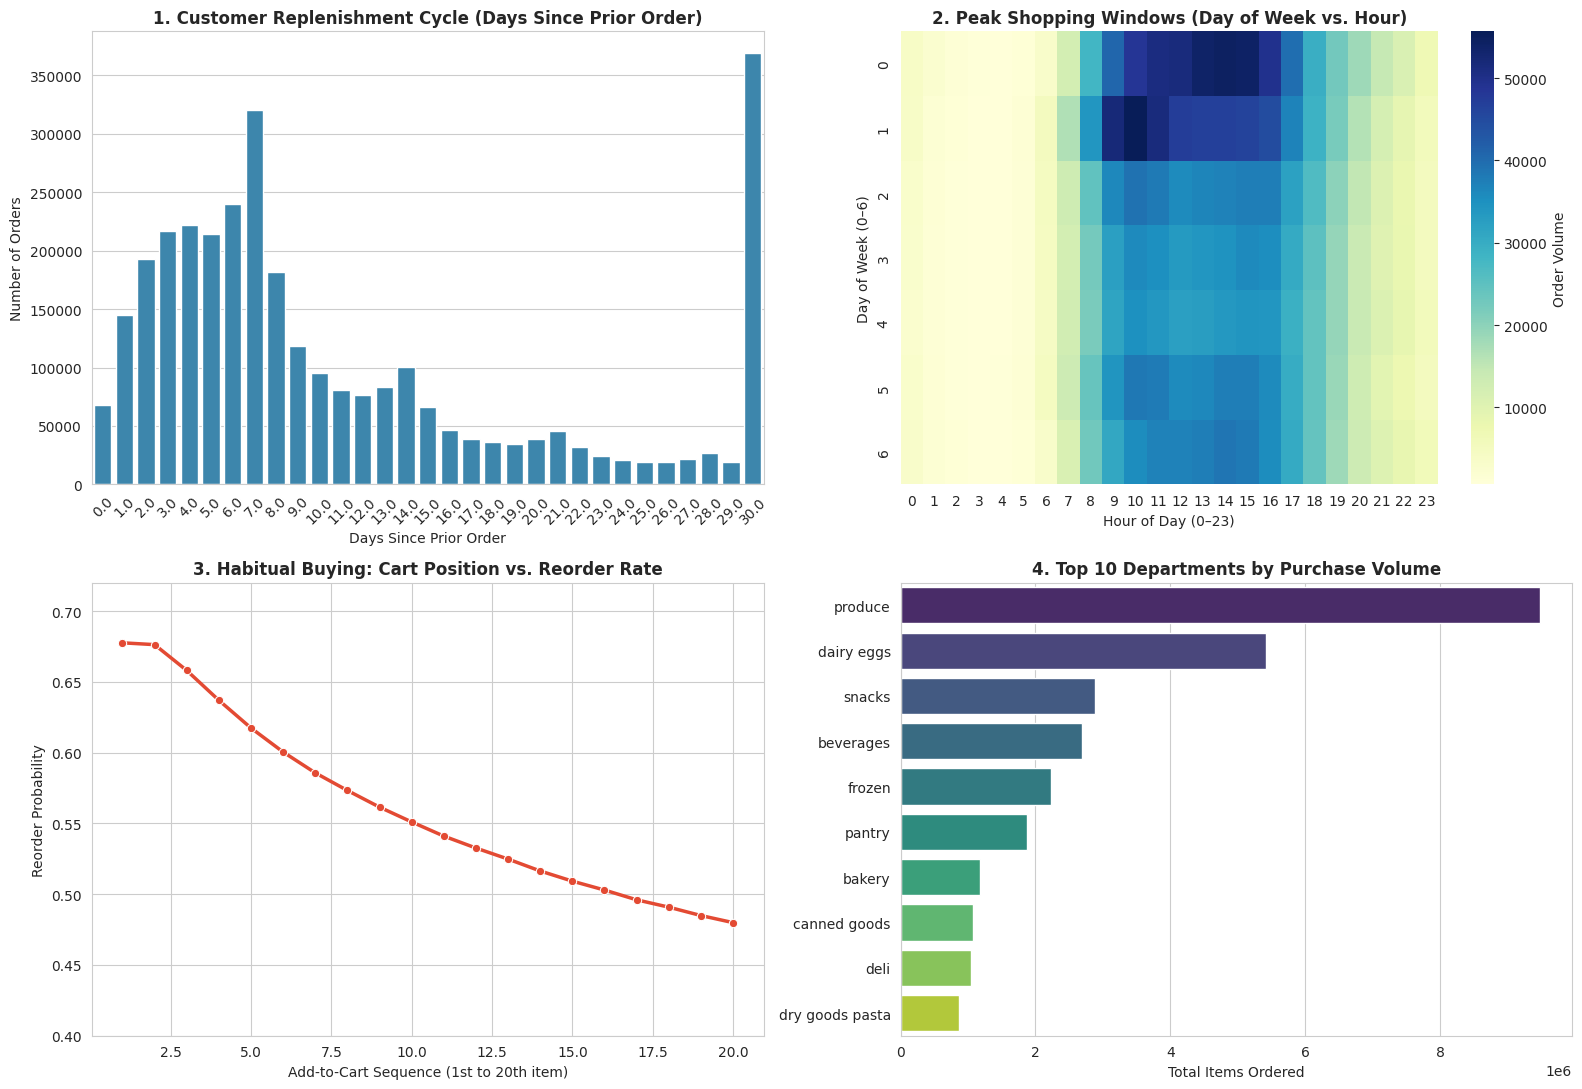

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Data Quality & Business Baseline Checks
print("--- Missing Values in Orders ---")
print(orders.isnull().sum())
print(f"\nPrior Reorder Rate: {prior['reordered'].mean():.2%}")
print(f"Train Reorder Rate: {train['reordered'].mean():.2%}")

# 2. Merge product metadata for readable EDA
product_meta = (
    products
    .merge(aisles, on='aisle_id', how='left')
    .merge(departments, on='department_id', how='left')
)

# 3. 4-Panel Portfolio Visualizations
sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
ax0, ax1, ax2, ax3 = axes.flatten()

# Chart 1: Replenishment Cycle
sns.countplot(
    data=orders.dropna(subset=['days_since_prior_order']),
    x='days_since_prior_order',
    ax=ax0,
    color='#2b8cbe'
)
ax0.set_title('1. Customer Replenishment Cycle (Days Since Prior Order)', fontsize=12, fontweight='bold')
ax0.set_xlabel('Days Since Prior Order')
ax0.set_ylabel('Number of Orders')
ax0.tick_params(axis='x', rotation=45)

# Chart 2: Ordering Heatmap (Day vs Hour)
dow_hour = orders.groupby(['order_dow', 'order_hour_of_day'])['order_id'].count().unstack()
sns.heatmap(dow_hour, cmap='YlGnBu', ax=ax1, cbar_kws={'label': 'Order Volume'})
ax1.set_title('2. Peak Shopping Windows (Day of Week vs. Hour)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Hour of Day (0–23)')
ax1.set_ylabel('Day of Week (0–6)')

# Chart 3: Add-to-Cart Order vs Reorder Rate
cart_reorder = (
    prior[prior['add_to_cart_order'] <= 20]
    .groupby('add_to_cart_order')['reordered']
    .mean()
    .reset_index()
)
sns.lineplot(
    data=cart_reorder,
    x='add_to_cart_order',
    y='reordered',
    marker='o',
    ax=ax2,
    color='#e34a33',
    linewidth=2.5
)
ax2.set_title('3. Habitual Buying: Cart Position vs. Reorder Rate', fontsize=12, fontweight='bold')
ax2.set_xlabel('Add-to-Cart Sequence (1st to 20th item)')
ax2.set_ylabel('Reorder Probability')
ax2.set_ylim(0.4, 0.72)

# Chart 4: Top 10 Departments by Purchase Volume
dept_stats = (
    prior[['product_id', 'reordered']]
    .merge(product_meta[['product_id', 'department']], on='product_id', how='left')
    .groupby('department')
    .agg(total_items=('reordered', 'count'))
    .sort_values('total_items', ascending=False)
    .head(10)
    .reset_index()
)
sns.barplot(
    data=dept_stats,
    x='total_items',
    y='department',
    ax=ax3,
    hue='department',
    palette='viridis',
    legend=False
)
ax3.set_title('4. Top 10 Departments by Purchase Volume', fontsize=12, fontweight='bold')
ax3.set_xlabel('Total Items Ordered')
ax3.set_ylabel('')

plt.tight_layout()
plt.savefig('01_eda_customer_shopping_patterns.png', dpi=300, bbox_inches='tight')
plt.show()

**02. Market Basket Analysis (Association Rules)**(FP_Growth&Generate Assocation Rule)

Basket matrix shape: (2351240, 100)
Frequent itemsets found: 271

--- Top 10 Product Association Rules (Sorted by Lift) ---
           antecedents_str            consequents_str  support  confidence     lift
      Lime Sparkling Water Sparkling Water Grapefruit 0.005650    0.285395 8.842637
Sparkling Water Grapefruit       Lime Sparkling Water 0.005650    0.175052 8.842637
                     Limes           Bunched Cilantro 0.005313    0.088824 4.586990
          Bunched Cilantro                      Limes 0.005313    0.274347 4.586990
                     Limes           Organic Cilantro 0.007471    0.124905 4.224173
          Organic Cilantro                      Limes 0.007471    0.252647 4.224173
            Organic Garlic       Organic Yellow Onion 0.009388    0.201069 4.168026
      Organic Yellow Onion             Organic Garlic 0.009388    0.194603 4.168026
              Strawberries                Raspberries 0.005149    0.084686 3.454510
               Raspberries          

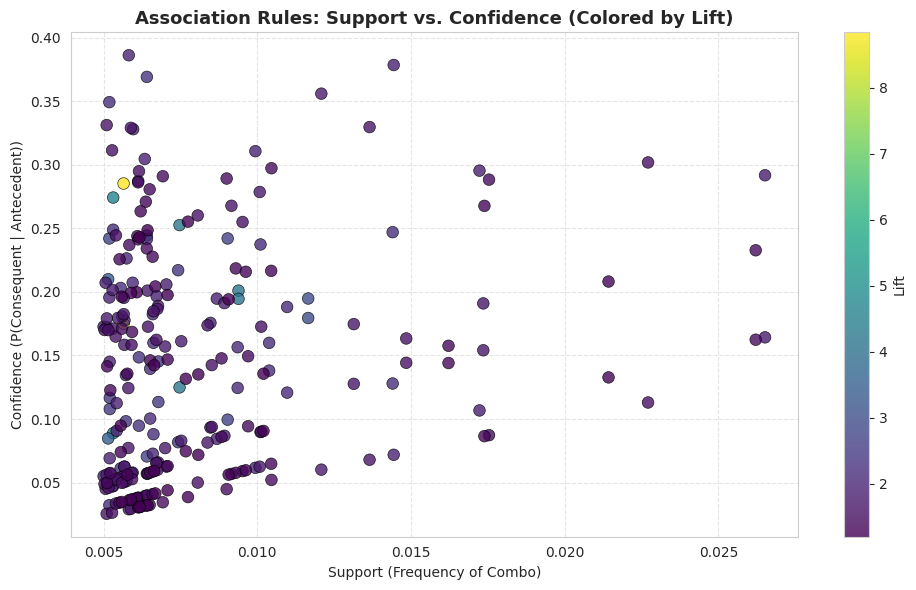

In [10]:
import warnings
warnings.filterwarnings("ignore")
from mlxtend.frequent_patterns import fpgrowth, association_rules
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter to top 100 most frequently purchased products (keeps RAM low & removes rare noise)
top_100_ids = prior['product_id'].value_counts().head(100).index
basket_df = (
    prior[prior['product_id'].isin(top_100_ids)]
    .merge(product_meta[['product_id', 'product_name']], on='product_id', how='left')
)

# 2. Build one-hot encoded Order x Product matrix using boolean (saves ~85% RAM)
basket_matrix = (
    basket_df.groupby(['order_id', 'product_name'])['product_id']
    .count()
    .unstack(fill_value=0)
    .astype(bool)
)

print(f"Basket matrix shape: {basket_matrix.shape}")

# 3. Mine frequent itemsets using FP-Growth (min_support = 0.5% of orders containing top-100 items)
frequent_itemsets = fpgrowth(basket_matrix, min_support=0.005, use_colnames=True)
print(f"Frequent itemsets found: {len(frequent_itemsets)}")

# 4. Generate association rules sorted by Lift
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.2)
rules = rules.sort_values(by='lift', ascending=False)

# Format readable rule strings
rules['antecedents_str'] = rules['antecedents'].apply(lambda x: ', '.join(list(x)))
rules['consequents_str'] = rules['consequents'].apply(lambda x: ', '.join(list(x)))

print("\n--- Top 10 Product Association Rules (Sorted by Lift) ---")
print(rules[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']].head(10).to_string(index=False))

# 5. Visualize Support vs. Confidence colored by Lift
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    rules['support'],
    rules['confidence'],
    c=rules['lift'],
    cmap='viridis',
    alpha=0.8,
    s=70,
    edgecolors='k',
    linewidth=0.5
)
plt.colorbar(scatter, label='Lift')
plt.title('Association Rules: Support vs. Confidence (Colored by Lift)', fontsize=13, fontweight='bold')
plt.xlabel('Support (Frequency of Combo)')
plt.ylabel('Confidence (P(Consequent | Antecedent))')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('02_association_rules_lift.png', dpi=300, bbox_inches='tight')
plt.show()

## 03. Customer Segmentation (PCA & K-Means Clustering)

User-Aisle matrix shape: (206209, 134)
Explained variance by 6 components: 43.95%


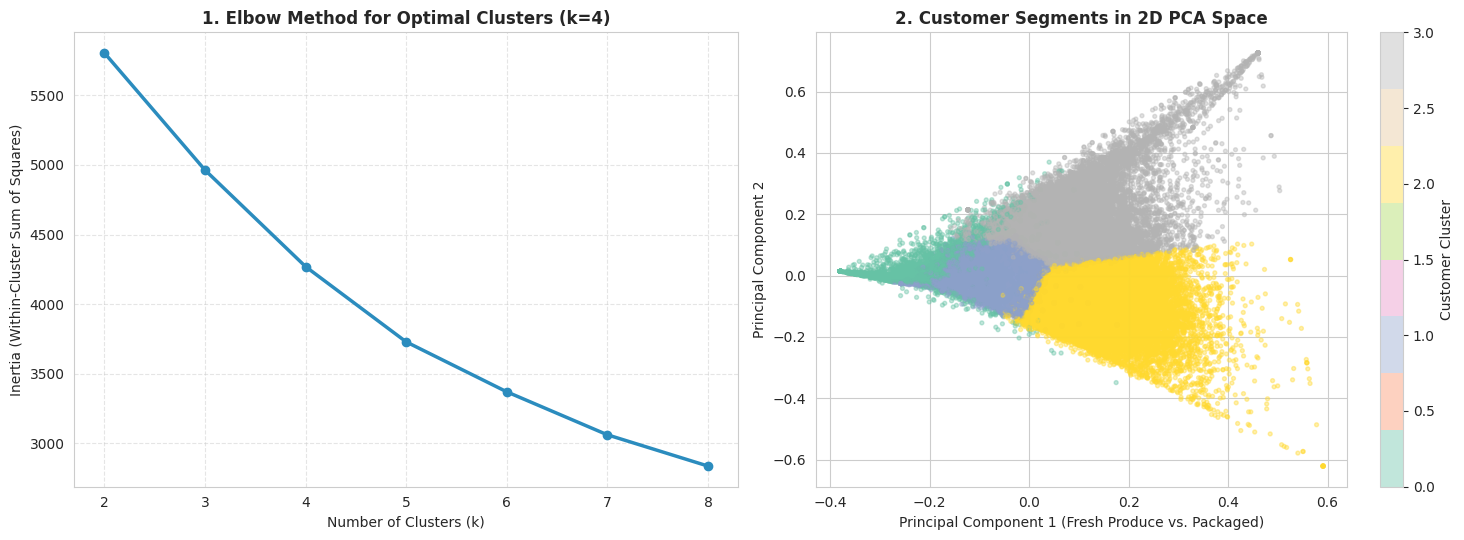


--- Customer Persona Profiles (Top 3 Aisles per Cluster) ---
Cluster 0 (5,696 users): water seltzer sparkling water (38.0%), soft drinks (5.1%), fresh fruits (4.3%)
Cluster 1 (105,165 users): fresh fruits (5.7%), yogurt (4.2%), fresh vegetables (4.2%)
Cluster 2 (62,769 users): fresh vegetables (21.0%), fresh fruits (11.8%), packaged vegetables fruits (6.7%)
Cluster 3 (32,579 users): fresh fruits (24.5%), packaged vegetables fruits (7.0%), packaged produce (6.4%)


In [11]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Merge prior orders with user_id and aisle name
user_aisle_df = (
    prior[['order_id', 'product_id']]
    .merge(orders[['order_id', 'user_id']], on='order_id', how='inner')
    .merge(product_meta[['product_id', 'aisle']], on='product_id', how='inner')
)

# 2. Build User x Aisle purchase matrix and normalize by row (share of each user's basket)
user_aisle_matrix = pd.crosstab(user_aisle_df['user_id'], user_aisle_df['aisle'])
user_aisle_norm = user_aisle_matrix.div(user_aisle_matrix.sum(axis=1), axis=0)
print(f"User-Aisle matrix shape: {user_aisle_norm.shape}")

# 3. Apply PCA to compress 134 aisles into top 6 principal components
pca = PCA(n_components=6, random_state=42)
pca_features = pca.fit_transform(user_aisle_norm)
print(f"Explained variance by 6 components: {pca.explained_variance_ratio_.sum():.2%}")

# 4. Elbow Method to justify choosing k=4 clusters
inertia = []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(pca_features)
    inertia.append(km.inertia_)

# 5. Fit final K-Means model with k=4 customer segments
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
user_aisle_norm['cluster'] = kmeans.fit_predict(pca_features)

# 6. Visualize Elbow Curve + 2D PCA Cluster Projection
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

ax1.plot(K_range, inertia, marker='o', linewidth=2.5, color='#2b8cbe')
ax1.set_title('1. Elbow Method for Optimal Clusters (k=4)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia (Within-Cluster Sum of Squares)')
ax1.grid(True, linestyle='--', alpha=0.5)

scatter = ax2.scatter(
    pca_features[:, 0], pca_features[:, 1],
    c=user_aisle_norm['cluster'], cmap='Set2', alpha=0.4, s=8
)
ax2.set_title('2. Customer Segments in 2D PCA Space', fontsize=12, fontweight='bold')
ax2.set_xlabel('Principal Component 1 (Fresh Produce vs. Packaged)')
ax2.set_ylabel('Principal Component 2')
plt.colorbar(scatter, ax=ax2, label='Customer Cluster')

plt.tight_layout()
plt.savefig('03_customer_segmentation_pca_kmeans.png', dpi=300, bbox_inches='tight')
plt.show()

# 7. Profile each cluster's top 3 signature aisles
print("\n--- Customer Persona Profiles (Top 3 Aisles per Cluster) ---")
cluster_means = user_aisle_norm.groupby('cluster').mean()
for c in range(4):
    top_aisles = cluster_means.loc[c].sort_values(ascending=False).head(3)
    summary = ", ".join([f"{aisle} ({val:.1%})" for aisle, val in top_aisles.items()])
    print(f"Cluster {c} ({(user_aisle_norm['cluster']==c).sum():,} users): {summary}")

## 04. Reorder Prediction Model (Feature Engineering & LightGBM)

Total candidate (user, product) pairs: 8,474,661 | Positive reorder rate: 9.78%
[LightGBM] [Info] Number of positive: 663668, number of negative: 6114053
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.266502 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1587
[LightGBM] [Info] Number of data points in the train set: 6777721, number of used features: 11
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.097919 -> initscore=-2.220563
[LightGBM] [Info] Start training from score -2.220563

Validation ROC-AUC: 0.8304
Validation F1-Score (threshold=0.22): 0.4340


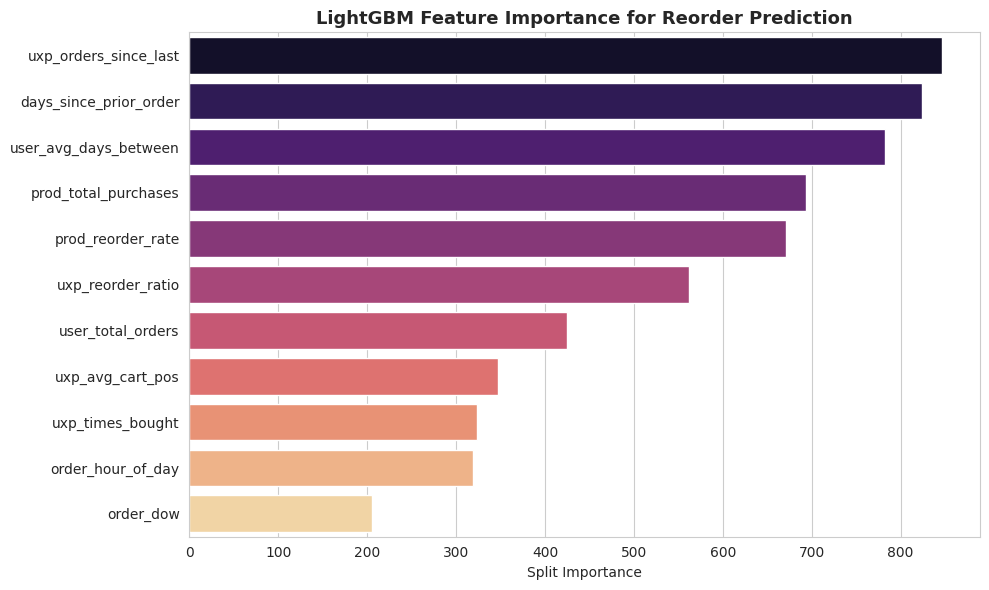

In [12]:



import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Identify users in the 'train' split (131,209 users whose next basket is known)
train_orders = orders[orders['eval_set'] == 'train'][['order_id', 'user_id', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order']]
train_users = train_orders['user_id'].unique()

# Filter prior orders to train_users so feature engineering stays fast & RAM-safe
prior_orders = orders[(orders['eval_set'] == 'prior') & (orders['user_id'].isin(train_users))]
prior_items = prior.merge(prior_orders[['order_id', 'user_id', 'order_number', 'days_since_prior_order']], on='order_id', how='inner')

# 2. Engineer User-Level Features
user_feats = prior_orders.groupby('user_id').agg(
    user_total_orders=('order_number', 'max'),
    user_avg_days_between=('days_since_prior_order', 'mean')
).reset_index()

# 3. Engineer Product-Level Features
prod_feats = prior_items.groupby('product_id').agg(
    prod_total_purchases=('order_id', 'count'),
    prod_reorder_rate=('reordered', 'mean')
).reset_index()

# 4. Engineer User x Product Interaction Features (Candidate Pairs)
uxp_feats = prior_items.groupby(['user_id', 'product_id']).agg(
    uxp_times_bought=('order_id', 'count'),
    uxp_last_order_num=('order_number', 'max'),
    uxp_avg_cart_pos=('add_to_cart_order', 'mean')
).reset_index()

# 5. Merge features + Recency & Purchase Rate ratios
data = (
    uxp_feats
    .merge(user_feats, on='user_id', how='left')
    .merge(prod_feats, on='product_id', how='left')
    .merge(train_orders[['user_id', 'order_id', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order']], on='user_id', how='left')
)

data['uxp_reorder_ratio'] = data['uxp_times_bought'] / data['user_total_orders']
data['uxp_orders_since_last'] = data['order_number'] - data['uxp_last_order_num']

# 6. Attach Ground-Truth Target (1 if reordered in the 'train' basket, else 0)
train_labels = train[['order_id', 'product_id']].copy()
train_labels['target'] = 1

data = data.merge(train_labels, on=['order_id', 'product_id'], how='left')
data['target'] = data['target'].fillna(0).astype('int8')

print(f"Total candidate (user, product) pairs: {len(data):,} | Positive reorder rate: {data['target'].mean():.2%}")

# 7. Train/Validation Split by User (prevents data leakage across same user!)
feature_cols = [
    'uxp_times_bought', 'uxp_reorder_ratio', 'uxp_orders_since_last', 'uxp_avg_cart_pos',
    'user_total_orders', 'user_avg_days_between',
    'prod_total_purchases', 'prod_reorder_rate',
    'order_dow', 'order_hour_of_day', 'days_since_prior_order'
]

train_u, val_u = train_test_split(train_users, test_size=0.2, random_state=42)
X_train = data[data['user_id'].isin(train_u)][feature_cols]
y_train = data[data['user_id'].isin(train_u)]['target']
X_val = data[data['user_id'].isin(val_u)][feature_cols]
y_val = data[data['user_id'].isin(val_u)]['target']

# 8. Train LightGBM Classifier
model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.08,
    num_leaves=31,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)

# 9. Evaluate ROC-AUC & F1 at optimal probability threshold (0.22 for imbalanced ~10% positive rate)
val_probs = model.predict_proba(X_val)[:, 1]
val_preds = (val_probs >= 0.22).astype(int)

print(f"\nValidation ROC-AUC: {roc_auc_score(y_val, val_probs):.4f}")
print(f"Validation F1-Score (threshold=0.22): {f1_score(y_val, val_preds):.4f}")

# 10. Plot Feature Importance
imp_df = pd.DataFrame({'Feature': feature_cols, 'Importance': model.feature_importances_}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=imp_df, x='Importance', y='Feature', hue='Feature', palette='magma', legend=False)
plt.title('LightGBM Feature Importance for Reorder Prediction', fontsize=13, fontweight='bold')
plt.xlabel('Split Importance')
plt.ylabel('')
plt.tight_layout()
plt.savefig('04_reorder_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

## 05. Key Business Takeaways & Recommendations
* **Replenishment & Timing (EDA):** ~59% of all purchased items are reorders, with sharp weekly (7-day) and monthly (30-day) shopping cycles. The 1st item added to a cart has a ~68% reorder probability, confirming habitual shopping behavior.
* **Cross-Sell Bundles (FP-Growth):** High-lift rules (*Organic Cilantro → Limes*, Lift 4.22; *Yellow Onion ↔ Garlic*, Lift 4.17) identify true culinary affinities for checkout "Frequently Bought Together" widgets.
* **Targeted Marketing (PCA + K-Means):** 206K+ shoppers segment into 4 distinct behavioral personas (e.g., Hydration/Beverage loyalists vs. Balanced Fresh-Food shoppers), enabling personalized home-screen banners.
* **Next-Basket Engine (LightGBM):** Trained on 8.47M user-product pairs using recency, frequency, and cart-position features (achieving **0.8304 ROC-AUC** and **0.4340 F1** at a 0.22 probability threshold) to power a "Buy It Again" carousel.